[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/15-projects/p01-ml-classifier-pipeline/colab_quickstart.ipynb)

# P1 quickstart - classic classifiers in a scikit-learn Pipeline

This notebook downloads the project (in Colab), installs its packages, runs it and shows the results. Locally it uses the folder you already have. CPU is enough.

## 1. Get the code
In Colab this clones the repo. If the project folder already exists, the clone is skipped.

In [1]:
import os, subprocess, sys
from pathlib import Path

PROJECT = "15-projects/p01-ml-classifier-pipeline"
if Path("main.py").exists() and Path("requirements.txt").exists():
    print("Already inside the project folder - no clone needed.")
elif Path("../../" + PROJECT).exists():
    os.chdir("../../" + PROJECT)          # repo already on disk two levels up
else:
    if not Path("AI-Engineer").exists():  # first run in Colab: download the repo
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/vvvvvivekkk/AI-Engineer.git"], check=True)
    os.chdir(Path("AI-Engineer") / PROJECT)
print("Working folder:", Path.cwd())

Already inside the project folder - no clone needed.
Working folder: /home/claude/AI-Engineer/15-projects/p01-ml-classifier-pipeline


## 2. Install packages (Colab only)

In [2]:
import sys, subprocess
from pathlib import Path
# Only install in Colab. Locally you already did "pip install -r requirements.txt" in a venv.
# Colab ships its own PyTorch, so we skip the torch line to save a big download.
if "google.colab" in sys.modules:
    reqs = [l for l in Path("requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith(("#", "torch"))]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=True)
    print("installed", len(reqs), "packages")
else:
    print("Not in Colab - skipping install.")

Not in Colab - skipping install.


## 3. (Re)create the sample data
The CSVs are already committed; this shows where they come from.

In [3]:
!{sys.executable} make_data.py

wrote wine.csv: 178 rows, 13 feature columns
wrote iris.csv: 150 rows, 4 feature columns


wrote breast_cancer.csv: 569 rows, 30 feature columns


## 4. Run the experiment on all three datasets
Takes about 20 seconds on a CPU.

In [4]:
!{sys.executable} main.py


=== wine ===
              model  cv_accuracy_mean  cv_accuracy_std  cv_f1_macro_mean
logistic_regression             0.979            0.028             0.980
      random_forest             0.979            0.028             0.979
                knn             0.951            0.035             0.951
      decision_tree             0.902            0.059             0.905
best: logistic_regression | test accuracy 0.972 | test F1-macro 0.971 | 2.0s



=== iris ===
              model  cv_accuracy_mean  cv_accuracy_std  cv_f1_macro_mean
logistic_regression             0.958            0.026             0.958
                knn             0.958            0.026             0.958
      decision_tree             0.950            0.017             0.950
      random_forest             0.950            0.031             0.949
best: logistic_regression | test accuracy 1.000 | test F1-macro 1.000 | 1.4s



=== breast_cancer ===
              model  cv_accuracy_mean  cv_accuracy_std  cv_f1_macro_mean
logistic_regression             0.978            0.010             0.976
      random_forest             0.963            0.018             0.960
                knn             0.963            0.011             0.960
      decision_tree             0.916            0.018             0.912
best: logistic_regression | test accuracy 0.974 | test F1-macro 0.972 | 2.2s

Reports written to /home/claude/AI-Engineer/15-projects/p01-ml-classifier-pipeline/reports


## 5. Look at one report and its confusion matrix

# Report: breast_cancer

Rows: 569 (train 455, test 114), features: 30, classes: malignant, benign

## 5-fold cross-validation on the training set

| model               |   cv_accuracy_mean |   cv_accuracy_std |   cv_f1_macro_mean |
|:--------------------|-------------------:|------------------:|-------------------:|
| logistic_regression |              0.978 |             0.010 |              0.976 |
| random_forest       |              0.963 |             0.018 |              0.960 |
| knn                 |              0.963 |             0.011 |              0.960 |
| decision_tree       |              0.916 |             0.018 |              0.912 |

## Tuned winner: logistic_regression

Best settings: `{'model__C': 0.1}` (CV F1-macro 0.981)

## Hidden test set (used once)

Accuracy 0.974, F1-macro 0.972

```
              precision    recall  f1-score   support

   malignant      0.976     0.952     0.964        42
      benign      0.973     0.986     0.979        72

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114
```

![confusion matrix](confusion_breast_cancer.png)

## Which mistakes matter?

Missed cancers (false negatives): 2. False alarms (false positives): 1. In screening, a false negative is far more costly, so we would accept more false alarms to push false negatives toward zero (e.g. by lowering the decision threshold).


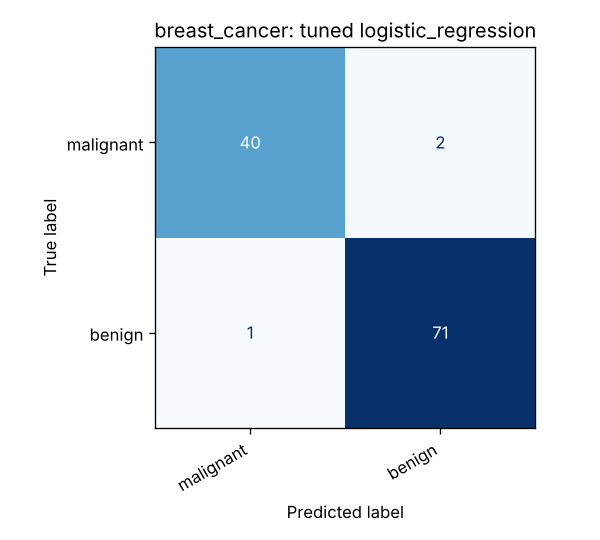

In [5]:
from IPython.display import Markdown, Image, display
display(Markdown(Path('reports/report_breast_cancer.md').read_text()))
display(Image('reports/confusion_breast_cancer.png'))

## 6. Run the tests
`pytest` runs every function whose name starts with `test_`.

In [6]:
!{sys.executable} -m pytest -q

.

..

.

.                                                                    [100%]
5 passed in 6.09s
